# 04 — Score questions and run simple comparison rules

**Goal:** understand the scoring rule and establish the strategies our controller must beat. Information is measured in bits; effort is measured in actual simulated seconds.
**Reward = information − lambda × seconds.** A negative score does not mean negative information; it means the time charge exceeded the information gained.
Code: [channel.py](../src/sim/channel.py), [baselines.py](../src/control/baselines.py).
These are Stage-1 simulated sessions, not classifier-accuracy results.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from src.common import save_run, load_calibration, load_contexts
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot(name):
    plt.tight_layout()
    plt.savefig(folder / f'{name}.png', dpi=150)
    plt.show()

## 1. Load permitted inputs and check the simulator gate

In [2]:
assert json.loads((project / 'outputs/sim_validation/gate.json').read_text())['passed']
from src.sim.fatigue import Scenario
from src.sim.channel import ACTION_NAMES
from src.eval.stage1 import PlanningModel, population_model, benchmark, summarize
contexts = load_contexts()
population = population_model(load_calibration())
scenario = Scenario(beta=1)
folder = save_run('notebook04', {'scenario': scenario.dictionary(), 'episodes': 500})
model = PlanningModel(contexts, scenario, population)
print('Contexts:', len(contexts['image_id']), '| lambda:', scenario.lam, 'bits per second')

Contexts: 2000 | lambda: 1.0 bits per second


## 2. See the actual model confidence going into Stage 1
Each classifier checkpoint contributes its 500 most uncertain remaining pool images.
The stream is sampled equally across the four checkpoints. We are not retraining a classifier here.

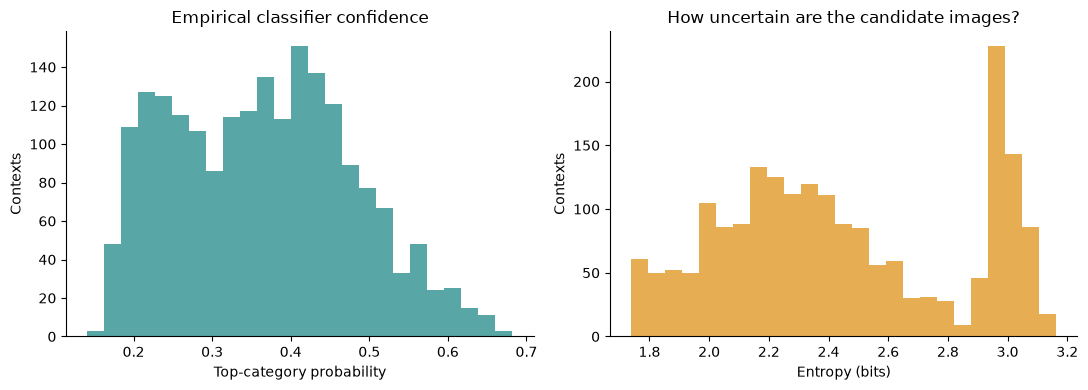

In [3]:
probability = contexts['probabilities']
entropy = -(probability * np.log2(probability.clip(1e-12))).sum(1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(probability.max(1), bins=25, color='#58a6a6')
axes[0].set(xlabel='Top-category probability', ylabel='Contexts', title='Empirical classifier confidence')
axes[1].hist(entropy, bins=25, color='#e7ad52')
axes[1].set(xlabel='Entropy (bits)', ylabel='Contexts', title='How uncertain are the candidate images?')
show_plot('01_stage1_context_distribution')

## 3. Compare question information, time, and reward
These are population-model expectations. Higher fatigue changes both reliability and response time in our assumed model. Gold checks have zero label information: their value can only come from better future decisions.

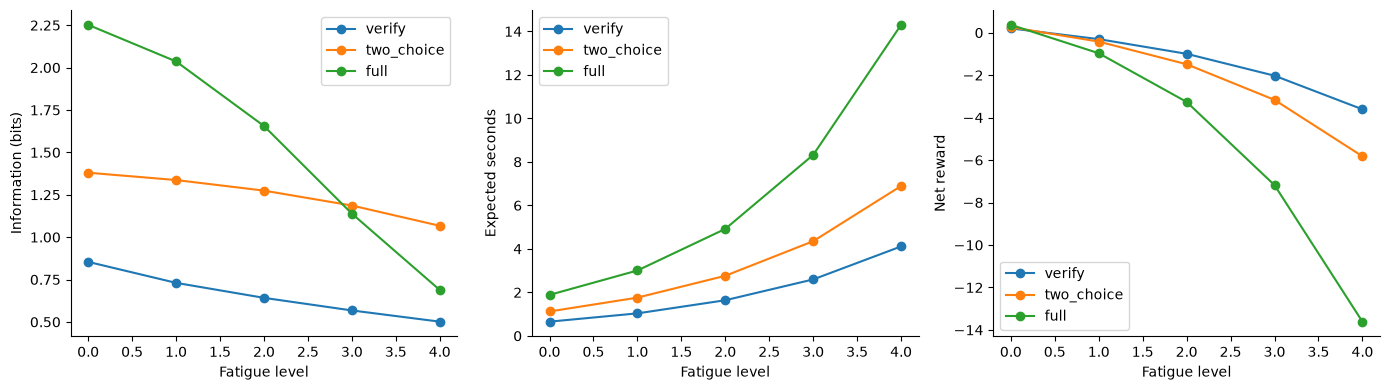

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for action in [1, 2, 3]:
    for ax, values in zip(axes, [model.information, model.seconds, model.reward]):
        ax.plot(range(5), values[:, :, action].mean(0), 'o-', label=ACTION_NAMES[action])
for ax, label in zip(axes, ['Information (bits)', 'Expected seconds', 'Net reward']):
    ax.set(xlabel='Fatigue level', ylabel=label)
    ax.legend()
show_plot('02_information_time_and_reward')

## 4. Run eight baseline strategies on the same simulated sessions
We use 500 different validation people, matching people, candidate streams, and random tapes across policies within each condition. Random question selection uses a separate random stream. The workload-gap and exponential rules are transparent published-style adaptations, not reimplementations of every component of the original papers.

In [5]:
policies = ['full', 'two_choice', 'verify', 'random', 'alternating', 'exp_decay', 'gap_workload', 'blind']
baseline_tables = []
for beta in [0., 1., 2.]:
    condition = Scenario(model='None' if beta == 0 else 'Markov', beta=beta)
    table, path = benchmark(contexts, condition, policies, episodes=500)
    table['beta'] = beta
    baseline_tables.append(table)
baselines = pd.concat(baseline_tables, ignore_index=True)
baselines.to_csv(folder / 'baseline_episodes.csv.gz', index=False)
display(summarize(baselines[baselines.beta == 1]).round(3))

,reward,information,seconds,error_rate,tracking_error,bits_per_second,reward_se
policy,,,,,,,
verify,-18.742,112.556,131.299,0.037,0.142,0.857,2.951
two_choice,-116.181,184.364,300.545,0.052,0.212,0.613,7.664
alternating,-183.009,187.212,370.221,0.093,0.220,0.506,10.359
random,-185.708,186.872,372.580,0.096,0.217,0.502,10.496
blind,-248.715,232.561,481.276,0.121,0.241,0.483,14.043
gap_workload,-389.381,234.145,623.526,0.182,0.264,0.376,13.735
full,-641.224,246.474,887.698,0.261,0.260,0.278,25.462
exp_decay,-715.618,108.385,824.003,0.045,0.093,0.132,2.742


## 5. Compare baseline scores and information per second
Each marker averages 500 sessions. We will add planning controllers next.

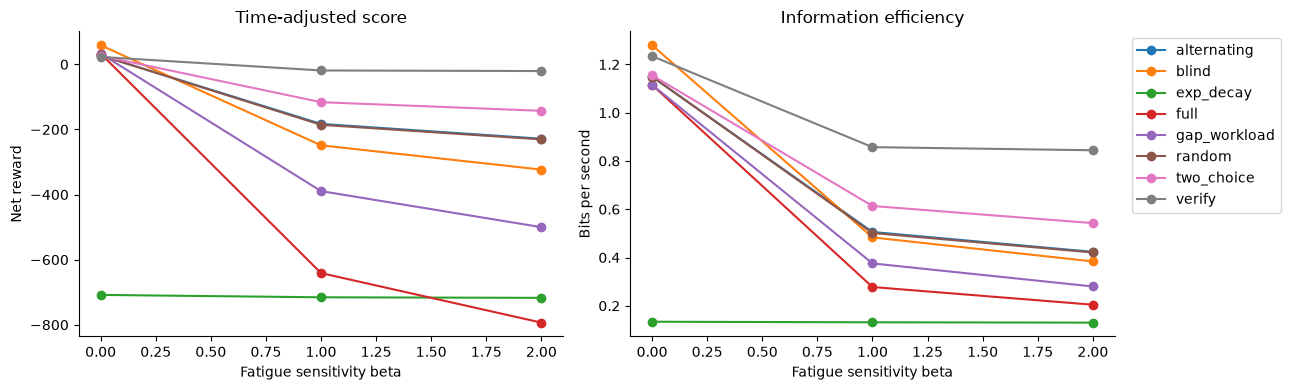

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, group in baselines.groupby('policy'):
    summary = group.groupby('beta')[['reward', 'information', 'seconds']].mean()
    axes[0].plot(summary.index, summary.reward, 'o-', label=name)
    axes[1].plot(summary.index, summary.information / summary.seconds, 'o-', label=name)
axes[0].set(xlabel='Fatigue sensitivity beta', ylabel='Net reward', title='Time-adjusted score')
axes[1].set(xlabel='Fatigue sensitivity beta', ylabel='Bits per second', title='Information efficiency')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
show_plot('03_baseline_comparisons')

## 6. Check that the probability and information calculations behave sensibly
Every answer-channel row must sum to one. Information must lie between zero and the picture's original uncertainty. Later notebooks also check the hidden-state boundary.

In [7]:
from src.sim.channel import answer_channel, mutual_information
p = contexts['probabilities'][:20]
for action in range(5):
    channel = answer_channel(p, contexts['difficulty'][:20], 2, action, 1, population['skill'], population['confusion'])
    assert np.allclose(channel.sum(2), 1)
    information = mutual_information(p, channel)
    uncertainty = -(p * np.log2(p.clip(1e-12))).sum(1)
    assert ((information >= 0) & (information <= uncertainty + 1e-8)).all()
print('Answer probability and information-bound checks passed.')

Answer probability and information-bound checks passed.
